# Notebook 3 – Categorical Feature Engineering

# Notebook 3 – Categorical Feature Engineering

## Introduction

Categorical Feature Engineering is the process of converting categorical data into meaningful numerical representations that Machine Learning algorithms can understand.

Categorical data represents labels, groups, names, or categories rather than measurable numerical quantities.

Examples:
- Gender
- City
- Department
- Education Level
- Payment Method
- Customer Type

### Topics Covered

1. Categorical Variables
2. Nominal Variables
3. Ordinal Variables
4. Binary Variables
5. One-Hot Encoding
6. Ordinal Encoding
7. Label Encoding
8. Frequency Encoding
9. Target Encoding
10. Rare Category Grouping
11. Category Cardinality
12. Handling Unknown Categories
13. Combining Categories

### Learning Objectives

- Understand different types of categorical variables.
- Learn different categorical encoding techniques.
- Understand the differences between encoding methods.
- Select the appropriate encoding technique.
- Handle rare and unknown categories.
- Create meaningful categorical features for Machine Learning.



## Step 1 – Import Required Libraries

We use the following libraries:

- Pandas: To create and manipulate categorical data.
- NumPy: To perform numerical operations.
- Matplotlib: To visualize categorical distributions.
- Scikit-learn: To apply categorical encoding techniques.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    LabelEncoder
)

from sklearn.model_selection import train_test_split

## Step 2 – Create a Sample Dataset

We will create a customer dataset containing different categorical variables.

The dataset includes:

- Customer_ID
- Gender
- City
- Education
- Membership
- Payment_Method
- Purchased

The Purchased column represents the target variable.

We will use this dataset to understand and implement categorical feature engineering techniques.

In [2]:
data = {
    "Customer_ID": range(101, 116),
    "Gender": [
        "Male", "Female", "Female", "Male", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male"
    ],
    "City": [
        "Chennai", "Mumbai", "Delhi", "Chennai", "Bangalore",
        "Mumbai", "Delhi", "Chennai", "Hyderabad", "Mumbai",
        "Chennai", "Bangalore", "Delhi", "Hyderabad", "Chennai"
    ],
    "Education": [
        "School", "Bachelor", "Master", "PhD", "Bachelor",
        "Master", "School", "Bachelor", "PhD", "Master",
        "Bachelor", "School", "Master", "Bachelor", "PhD"
    ],
    "Membership": [
        "Gold", "Silver", "Bronze", "Gold", "Silver",
        "Gold", "Bronze", "Silver", "Gold", "Bronze",
        "Gold", "Silver", "Bronze", "Gold", "Silver"
    ],
    "Payment_Method": [
        "UPI", "Card", "Cash", "UPI", "Card",
        "UPI", "Cash", "Card", "UPI", "Cash",
        "Card", "UPI", "Cash", "Card", "UPI"
    ],
    "Purchased": [
        1, 0, 1, 1, 0,
        1, 0, 1, 1, 0,
        1, 0, 0, 1, 1
    ]
}

df = pd.DataFrame(data)

df

,Customer_ID,Gender,City,Education,Membership,Payment_Method,Purchased
0,101,Male,Chennai,School,Gold,UPI,1
1,102,Female,Mumbai,Bachelor,Silver,Card,0
2,103,Female,Delhi,Master,Bronze,Cash,1
3,104,Male,Chennai,PhD,Gold,UPI,1
4,105,Male,Bangalore,Bachelor,Silver,Card,0
5,106,Female,Mumbai,Master,Gold,UPI,1
6,107,Male,Delhi,School,Bronze,Cash,0
7,108,Female,Chennai,Bachelor,Silver,Card,1
8,109,Male,Hyderabad,PhD,Gold,UPI,1
9,110,Female,Mumbai,Master,Bronze,Cash,0


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (15, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     15 non-null     int64 
 1   Gender          15 non-null     object
 2   City            15 non-null     object
 3   Education       15 non-null     object
 4   Membership      15 non-null     object
 5   Payment_Method  15 non-null     object
 6   Purchased       15 non-null     int64 
dtypes: int64(2), object(5)
memory usage: 972.0+ bytes

Categorical Columns:
['Gender', 'City', 'Education', 'Membership', 'Payment_Method']

Missing Values:
Customer_ID       0
Gender            0
City              0
Education         0
Membership        0
Payment_Method    0
Purchased         0
dtype: int64


## 1. Categorical Variables

### Step 1 – Understand the Concept

Categorical variables are features that represent groups, labels, or categories.

They describe the type or class of an observation rather than its numerical quantity.

Examples:
- Gender: Male, Female
- City: Chennai, Mumbai, Delhi
- Department: HR, IT, Finance
- Payment Method: Cash, Card, UPI

### When Should We Use Them?

Categorical variables are used when data represents names, groups, classifications, or types.

### Why Are They Important?

They provide information about the characteristics of customers, products, employees, and other observations.

### AI/ML Use Case

In customer purchase prediction, city, membership type, and payment method may help a model identify customer purchasing patterns.

### Important Note

Many Machine Learning algorithms require categorical values to be converted into numerical representations before training.


### Step 2 – Demonstrate the Concept

Consider the following customer information:

| Customer | City | Payment Method |
|---|---|---|
| 101 | Chennai | UPI |
| 102 | Mumbai | Card |
| 103 | Delhi | Cash |

City and Payment Method are categorical variables because they represent labels rather than measurable quantities.

In [4]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].unique())


Gender
['Male' 'Female']

City
['Chennai' 'Mumbai' 'Delhi' 'Bangalore' 'Hyderabad']

Education
['School' 'Bachelor' 'Master' 'PhD']

Membership
['Gold' 'Silver' 'Bronze']

Payment_Method
['UPI' 'Card' 'Cash']


### Step 3 – Implementation Explanation

We used select_dtypes() to identify columns containing categorical text data.

We used unique() to display the different categories in each column.

This helps us understand the categorical values before selecting an encoding technique.

## 2. Nominal Variables

### Step 1 – Understand the Concept

Nominal variables are categorical variables that have no natural order or ranking.

Examples:
- City: Chennai, Mumbai, Delhi
- Gender: Male, Female
- Payment Method: Cash, Card, UPI
- Department: HR, IT, Finance

### When Should We Use Them?

Use nominal variables when categories represent different groups without any meaningful ranking.

### Why Are They Important?

They help represent different types of observations without introducing an incorrect order.

### AI/ML Use Case

In customer segmentation, city and payment method can help identify different customer groups.

### Suitable Encoding Techniques

- One-Hot Encoding
- Frequency Encoding
- Target Encoding

The best technique depends on the number of categories and the dataset size.


### Step 2 – Demonstrate the Concept

Consider three cities:

- Chennai
- Mumbai
- Delhi

There is no natural ranking between these cities.

We should not assume that Chennai = 1, Mumbai = 2, and Delhi = 3 represents any meaningful numerical order.

In [5]:
print("Unique Cities:")
print(df["City"].unique())

print("\nCity Value Counts:")
print(df["City"].value_counts())

Unique Cities:
['Chennai' 'Mumbai' 'Delhi' 'Bangalore' 'Hyderabad']

City Value Counts:
City
Chennai      5
Mumbai       3
Delhi        3
Bangalore    2
Hyderabad    2
Name: count, dtype: int64


### Step 3 – Implementation Explanation

City is a nominal variable because its categories do not have a natural order.

Assigning arbitrary numbers may create a false sense of ranking.

One-Hot Encoding is often a suitable choice when the number of unique cities is small.

## 3. Ordinal Variables

### Step 1 – Understand the Concept

Ordinal variables are categorical variables that have a meaningful order or ranking.

Examples:
- Education: School, Bachelor, Master, PhD
- Satisfaction: Low, Medium, High
- Membership: Bronze, Silver, Gold
- Size: Small, Medium, Large

### When Should We Use Them?

Use ordinal variables when categories have a meaningful ranking.

### Why Are They Important?

They preserve the order of categories and help represent ranking information.

### AI/ML Use Case

In customer satisfaction prediction, satisfaction levels can be represented according to their natural order.

### Suitable Encoding Technique

Ordinal Encoding is generally suitable when the categories have a clear and meaningful order.

### Important Note

The numerical values represent category order. They do not necessarily represent equal distances between categories.



### Step 2 – Demonstrate the Concept

Consider education levels:

| Education | Rank |
|---|---:|
| School | 1 |
| Bachelor | 2 |
| Master | 3 |
| PhD | 4 |

The categories have a meaningful order based on education level.

This order can be represented using numerical values.

In [6]:
education_order = [
    "School",
    "Bachelor",
    "Master",
    "PhD"
]

print("Education Categories:")
print(education_order)

Education Categories:
['School', 'Bachelor', 'Master', 'PhD']


### Step 3 – Implementation Explanation

Education is an ordinal variable because the categories have a meaningful order.

Ordinal Encoding can represent these categories using the specified ranking.

We should define the correct category order based on domain knowledge rather than relying on alphabetical order.

## 4. Binary Variables

### Step 1 – Understand the Concept

Binary variables are categorical variables that contain only two possible categories.

Examples:
- Yes / No
- True / False
- Active / Inactive
- Male / Female (when represented in a dataset with only these two categories)

### When Should We Use Them?

Use binary variables when a feature has exactly two meaningful categories.

### Why Are They Important?

They simplify categorical information into two numerical states.

### AI/ML Use Case

In customer prediction, a subscription status can be represented as:

- Active = 1
- Inactive = 0

### Suitable Encoding Technique

Binary Mapping is usually a simple and suitable choice for two categories.

### Important Note

Choose the mapping carefully. A value of 1 does not automatically mean better, greater, or more important.



### Step 2 – Demonstrate the Concept

Suppose a customer has an active subscription.

| Subscription | Encoded Value |
|---|---:|
| Active | 1 |
| Inactive | 0 |

The two categories are represented using 0 and 1.

In [7]:
df["Gender_Binary"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

df[["Gender", "Gender_Binary"]]

,Gender,Gender_Binary
0,Male,0
1,Female,1
2,Female,1
3,Male,0
4,Male,0
5,Female,1
6,Male,0
7,Female,1
8,Male,0
9,Female,1


### Step 3 – Implementation Explanation

We used map() to convert Gender categories into numerical values.

- Male = 0
- Female = 1

This is an example of binary encoding.

The mapping is an arbitrary representation and does not imply that one category is greater than another.

## 5. One-Hot Encoding

### Step 1 – Understand the Concept

One-Hot Encoding converts each category into a separate binary column.

Each new column represents one category.

The value is:

- 1 if the observation belongs to that category.
- 0 otherwise.

### When Should We Use It?

Use One-Hot Encoding when:

- The feature is nominal.
- The number of unique categories is relatively small.
- Categories do not have a natural order.

### Why Should We Use It?

It prevents the model from assuming an artificial numerical ranking between categories.

### Real-World Example

An online shopping application may have payment methods such as UPI, Card, and Cash.

One-Hot Encoding creates separate columns for these payment methods.

### AI/ML Use Case

It is commonly used for customer classification, purchase prediction, and churn prediction.

### Advantages

- Simple to understand.
- Does not introduce artificial ranking.
- Works well for low-cardinality nominal features.

### Limitations

It creates additional columns. Features with many unique categories can produce a large and sparse dataset.



### Step 2 – Demonstrate the Concept

Original data:

| Payment Method |
|---|
| UPI |
| Card |
| Cash |

After One-Hot Encoding:

| Payment_UPI | Payment_Card | Payment_Cash |
|---:|---:|---:|
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 0 | 0 | 1 |

Each category receives its own column.

In [8]:
one_hot_df = pd.get_dummies(
    df["Payment_Method"],
    prefix="Payment",
    dtype=int
)

one_hot_df

,Payment_Card,Payment_Cash,Payment_UPI
0,0,0,1
1,1,0,0
2,0,1,0
3,0,0,1
4,1,0,0
5,0,0,1
6,0,1,0
7,1,0,0
8,0,0,1
9,0,1,0


In [9]:
one_hot_result = pd.concat(
    [df[["Payment_Method"]], one_hot_df],
    axis=1
)

one_hot_result

,Payment_Method,Payment_Card,Payment_Cash,Payment_UPI
0,UPI,0,0,1
1,Card,1,0,0
2,Cash,0,1,0
3,UPI,0,0,1
4,Card,1,0,0
5,UPI,0,0,1
6,Cash,0,1,0
7,Card,1,0,0
8,UPI,0,0,1
9,Cash,0,1,0


### Step 3 – Implementation Explanation

We used pd.get_dummies() to apply One-Hot Encoding.

The original Payment_Method column contains three categories:

- UPI
- Card
- Cash

The encoding creates three separate binary columns.

Each row receives 1 in the column representing its payment method and 0 in the other columns.

One-Hot Encoding is useful when nominal categories have relatively low cardinality.

## 6. Ordinal Encoding

### Step 1 – Understand the Concept

Ordinal Encoding converts ordered categorical values into numerical values based on a predefined ranking.

Example:

| Membership | Encoded Value |
|---|---:|
| Bronze | 1 |
| Silver | 2 |
| Gold | 3 |

### When Should We Use It?

Use Ordinal Encoding when:

- Categories have a meaningful order.
- The ranking is known.
- The numerical representation should preserve the order.

### Why Should We Use It?

It preserves the ranking information in categorical features.

### Real-World Example

A customer feedback system may use:

- Low = 1
- Medium = 2
- High = 3

### AI/ML Use Case

Ordinal Encoding can be useful in customer satisfaction prediction and risk-level classification.

### Important Note

Do not use Ordinal Encoding for nominal categories without a meaningful order. The numerical values may introduce misleading relationships.



### Step 2 – Demonstrate the Concept

Membership categories:

Bronze < Silver < Gold

We assign:

- Bronze = 1
- Silver = 2
- Gold = 3

This numerical representation preserves the membership ranking.

In [10]:
membership_order = [
    "Bronze",
    "Silver",
    "Gold"
]

ordinal_encoder = OrdinalEncoder(
    categories=[membership_order]
)

df["Membership_Encoded"] = ordinal_encoder.fit_transform(
    df[["Membership"]]
).astype(int)

df[["Membership", "Membership_Encoded"]]

,Membership,Membership_Encoded
0,Gold,2
1,Silver,1
2,Bronze,0
3,Gold,2
4,Silver,1
5,Gold,2
6,Bronze,0
7,Silver,1
8,Gold,2
9,Bronze,0


### Step 3 – Implementation Explanation

We imported OrdinalEncoder from Scikit-learn.

We provided the correct category order:

Bronze = 1st level
Silver = 2nd level
Gold = 3rd level

The encoder converts each category into a numerical representation while preserving the specified order.

Ordinal Encoding is suitable for ordered categorical features.

## 7. Label Encoding

### Step 1 – Understand the Concept

Label Encoding converts categorical labels into integer values.

Example:

| Category | Encoded Value |
|---|---:|
| Chennai | 0 |
| Delhi | 1 |
| Mumbai | 2 |

The encoder assigns an integer to each unique category.

### When Should We Use It?

Label Encoding is commonly used for target labels in classification problems.

It can convert class names into numerical target values.

### Why Should We Use It?

Many Machine Learning workflows require target labels to be represented numerically.

### Real-World Example

A customer classification target may contain:

- Low Risk
- Medium Risk
- High Risk

Label Encoding can convert these class names into integer labels.

### AI/ML Use Case

It is commonly used to encode the target variable in classification tasks.

### Important Difference

Label Encoding and Ordinal Encoding are not exactly the same.

- Label Encoding assigns integers to class labels, commonly the target variable.
- Ordinal Encoding converts ordered categorical input features using a defined category order.

### Important Note

For nominal input features, arbitrary integer values can introduce a false ranking. One-Hot Encoding may be more appropriate.



### Step 2 – Demonstrate the Concept

Suppose the target variable contains:

- No
- Yes

Label Encoding can convert the values into:

- No = 0
- Yes = 1

This allows the target labels to be used in a classification workflow.

In [11]:
label_encoder = LabelEncoder()

df["Purchased_Encoded"] = label_encoder.fit_transform(
    df["Purchased"].astype(str)
)

print("Original Labels:")
print(label_encoder.classes_)

print("\nEncoded Labels:")
print(df[["Purchased", "Purchased_Encoded"]])

Original Labels:
['0' '1']

Encoded Labels:
    Purchased  Purchased_Encoded
0           1                  1
1           0                  0
2           1                  1
3           1                  1
4           0                  0
5           1                  1
6           0                  0
7           1                  1
8           1                  1
9           0                  0
10          1                  1
11          0                  0
12          0                  0
13          1                  1
14          1                  1


### Step 3 – Implementation Explanation

We used LabelEncoder to convert the target labels into numerical values.

The original Purchased column contains two classes:

- 0
- 1

The encoded column represents the same two classes using integer labels.

In this example, the target was already numerical, so the transformation is only a demonstration.

In real classification projects, Label Encoding is more useful when the target contains text labels such as Yes/No or Approved/Rejected.

We generally avoid using LabelEncoder on nominal input features.

## 8. Frequency Encoding

### Step 1 – Understand the Concept

Frequency Encoding replaces each category with the number of times it appears in a feature.

Formula:

Frequency = Number of occurrences of a category

Example:

| City | Frequency |
|---|---:|
| Chennai | 5 |
| Mumbai | 3 |
| Delhi | 2 |

### When Should We Use It?

Use Frequency Encoding when:

- A categorical feature has many unique categories.
- Category occurrence patterns may be useful.
- One-Hot Encoding would create too many columns.

### Why Should We Use It?

It represents how frequently each category appears without creating a separate column for every category.

### Real-World Example

An e-commerce company may analyze how frequently customers purchase from different product categories.

### AI/ML Use Case

Frequency Encoding can help represent city, product, or merchant categories in predictive models.

### Limitation

Different categories may have the same frequency, so the original category identity can be lost.

### Important Note

For reliable evaluation, calculate frequency mappings from training data only and apply them to validation and test data.



### Step 2 – Demonstrate the Concept

Suppose the City column contains:

Chennai, Mumbai, Chennai, Delhi, Chennai, Mumbai

Frequency:

- Chennai = 3
- Mumbai = 2
- Delhi = 1

Each city is replaced by its occurrence count.

In [12]:
city_frequency = df["City"].value_counts(normalize=True)

df["City_Frequency"] = df["City"].map(city_frequency)

df[["City", "City_Frequency"]]

,City,City_Frequency
0,Chennai,0.333333
1,Mumbai,0.200000
2,Delhi,0.200000
3,Chennai,0.333333
4,Bangalore,0.133333
5,Mumbai,0.200000
6,Delhi,0.200000
7,Chennai,0.333333
8,Hyderabad,0.133333
9,Mumbai,0.200000


### Step 3 – Implementation Explanation

We used value_counts(normalize=True) to calculate the proportion of each city in the dataset.

Then we used map() to replace each city with its frequency.

For example, if Chennai appears in 5 out of 15 records, its frequency is 5/15.

Frequency Encoding is useful for high-cardinality categorical features.

For a real ML workflow, the frequency mapping must be learned from training data only.

## 9. Target Encoding

### Step 1 – Understand the Concept

Target Encoding replaces each category with the average value of the target variable for that category.

For binary classification:

Category Encoding = Average Target Value for the Category

Example:

If 4 out of 5 Chennai customers purchased a product:

Chennai Target Encoding = 4 / 5 = 0.80

### When Should We Use It?

Use Target Encoding when:

- A categorical feature has many unique categories.
- The target variable contains useful category-level patterns.
- One-Hot Encoding creates too many columns.

### Why Should We Use It?

It represents the relationship between a category and the target variable using a numerical value.

### Real-World Example

An online shopping company may calculate the historical purchase rate for each city.

### AI/ML Use Case

Target Encoding can be useful in customer purchase prediction, credit risk prediction, and sales classification.

### Advantages

- Can reduce the number of columns.
- Captures category-to-target relationships.
- Useful for high-cardinality features.

### Limitations

- Can overfit, especially for categories with very few records.
- May leak target information if applied incorrectly.
- Requires careful validation.

### Important Note: Prevent Data Leakage

Target Encoding must not be calculated using validation or test target values.

In production ML workflows, use out-of-fold target encoding or a suitable target encoder with cross-validation.

Smoothing can reduce the effect of categories with very few observations.



### Step 2 – Demonstrate the Concept

Suppose we have the following data:

| City | Purchased |
|---|---:|
| Chennai | 1 |
| Chennai | 1 |
| Chennai | 0 |
| Mumbai | 1 |
| Mumbai | 0 |

Chennai purchase rate:

(1 + 1 + 0) / 3 = 0.67

Mumbai purchase rate:

(1 + 0) / 2 = 0.50

These average target values can represent the categories.


In [13]:
target_data = pd.DataFrame({
    "City": [
        "Chennai", "Chennai", "Chennai",
        "Mumbai", "Mumbai",
        "Delhi", "Delhi", "Delhi"
    ],
    "Purchased": [1, 1, 0, 1, 0, 1, 1, 1]
})

target_data

,City,Purchased
0,Chennai,1
1,Chennai,1
2,Chennai,0
3,Mumbai,1
4,Mumbai,0
5,Delhi,1
6,Delhi,1
7,Delhi,1


In [14]:
target_mean = target_data.groupby("City")[
    "Purchased"
].mean()

target_data["City_Target_Encoded"] = (
    target_data["City"].map(target_mean)
)

target_data

,City,Purchased,City_Target_Encoded
0,Chennai,1,0.666667
1,Chennai,1,0.666667
2,Chennai,0,0.666667
3,Mumbai,1,0.500000
4,Mumbai,0,0.500000
5,Delhi,1,1.000000
6,Delhi,1,1.000000
7,Delhi,1,1.000000


### Step 3 – Implementation Explanation

We used groupby() to group records by City.

Then we calculated the mean of Purchased for each city.

For binary target values:

- 1 represents purchase.
- 0 represents no purchase.

The mean represents the purchase rate for each city.

This example demonstrates the basic calculation only.

It uses the complete demonstration dataset to calculate category averages. It must not be copied directly into a real train-test workflow because this can cause target leakage.

For real Machine Learning, use training-only out-of-fold target encoding and smoothing.

## 10. Rare Category Grouping

### Step 1 – Understand the Concept

Rare Category Grouping combines categories that appear very few times into a single group.

A common group name is "Other".

Example:

Before:

- Chennai = 100
- Mumbai = 80
- Delhi = 70
- Jaipur = 2
- Pune = 1

After grouping:

- Chennai = 100
- Mumbai = 80
- Delhi = 70
- Other = 3

### When Should We Use It?

Use rare category grouping when:

- A feature contains many categories.
- Some categories have very few observations.
- Rare categories create too many columns.
- Small category groups may lead to unstable estimates.

### Why Should We Use It?

It reduces unnecessary category complexity and helps create more stable features.

### Real-World Example

An e-commerce company may group products with very few sales into an "Other Products" category.

### AI/ML Use Case

It can help prepare high-cardinality customer, product, and location features for prediction.

### Important Note

Choose the rare-category threshold based on the training dataset and business meaning. Apply the same grouping rules to validation and test data.



### Step 2 – Demonstrate the Concept

Suppose a dataset contains:

- Chennai = 50 records
- Mumbai = 30 records
- Delhi = 20 records
- Jaipur = 2 records
- Pune = 1 record

If the minimum category count is 5:

Jaipur and Pune can be grouped into "Other".

In [15]:
city_counts = df["City"].value_counts()

minimum_count = 4

df["City_Grouped"] = df["City"].where(
    df["City"].map(city_counts) >= minimum_count,
    "Other"
)

df[["City", "City_Grouped"]]

,City,City_Grouped
0,Chennai,Chennai
1,Mumbai,Other
2,Delhi,Other
3,Chennai,Chennai
4,Bangalore,Other
5,Mumbai,Other
6,Delhi,Other
7,Chennai,Chennai
8,Hyderabad,Other
9,Mumbai,Other


In [16]:
print("Original Category Counts:")
print(df["City"].value_counts())

print("\nGrouped Category Counts:")
print(df["City_Grouped"].value_counts())

Original Category Counts:
City
Chennai      5
Mumbai       3
Delhi        3
Bangalore    2
Hyderabad    2
Name: count, dtype: int64

Grouped Category Counts:
City_Grouped
Other      10
Chennai     5
Name: count, dtype: int64


### Step 3 – Implementation Explanation

We used value_counts() to calculate the number of occurrences of each city.

We set minimum_count = 4.

Categories appearing fewer than four times were replaced with "Other".

This reduces the number of rare categories.

In this small example, cities with low counts may be grouped together.

In a real ML workflow, calculate category counts using training data only and reuse the same grouping rules for validation and test data.

## 11. Category Cardinality

### Step 1 – Understand the Concept

Category Cardinality refers to the number of unique categories present in a categorical feature.

Example:

A Gender column may contain:

- Male
- Female

Its cardinality is 2.

A City column may contain:

- Chennai
- Mumbai
- Delhi
- Bangalore
- Hyderabad

Its cardinality is 5.

### When Should We Use It?

Check category cardinality before selecting an encoding technique.

### Why Should We Use It?

It helps us understand the complexity of categorical features and avoid creating too many columns.

### Real-World Example

A customer dataset may contain hundreds of cities and thousands of product IDs.

### AI/ML Use Case

Cardinality analysis helps choose between One-Hot Encoding, Frequency Encoding, and Target Encoding.

### General Guidance

- Low cardinality: One-Hot Encoding may work well.
- Ordered categories: Ordinal Encoding may be appropriate.
- High cardinality: Frequency or Target Encoding may be considered.
- Very rare categories: Rare Category Grouping may help.

There is no universal numerical threshold for low or high cardinality. It depends on dataset size and model requirements.



### Step 2 – Demonstrate the Concept

Consider:

Gender:
- Male
- Female

Cardinality = 2

City:
- Chennai
- Mumbai
- Delhi
- Bangalore
- Hyderabad

Cardinality = 5

Product_ID:
- P101
- P102
- P103
- P104
- P105
- P106

Cardinality = 6

In [17]:
cardinality = df.select_dtypes(
    include="object"
).nunique()

print("Category Cardinality:")
print(cardinality)

Category Cardinality:
Gender            2
City              5
Education         4
Membership        3
Payment_Method    3
City_Grouped      2
dtype: int64


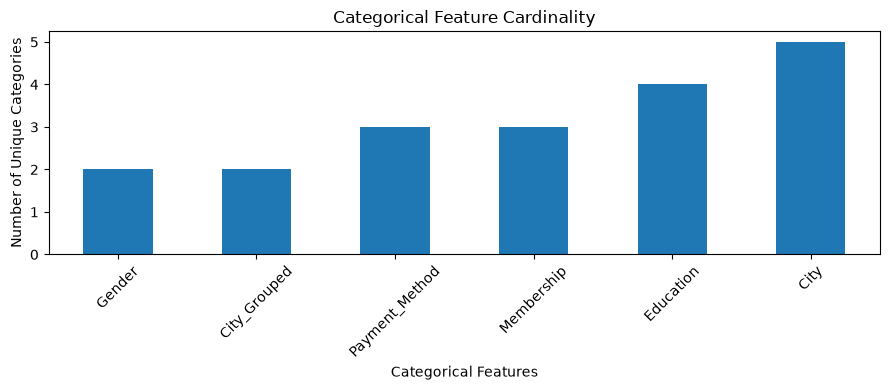

In [18]:
plt.figure(figsize=(9, 4))

cardinality.sort_values().plot(
    kind="bar",
    title="Categorical Feature Cardinality"
)

plt.xlabel("Categorical Features")
plt.ylabel("Number of Unique Categories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 3 – Implementation Explanation

We used nunique() to count the unique categories in each categorical feature.

The result shows the cardinality of each column.

A feature with more unique categories has higher cardinality.

Cardinality helps us select an appropriate encoding technique before model training.

## 12. Handling Unknown Categories

### Step 1 – Understand the Concept

Unknown categories are new categorical values that were not present when an encoder was fitted.

Example:

Training data contains:
- Chennai
- Mumbai
- Delhi

New prediction data contains:
- Chennai
- Mumbai
- Coimbatore

Coimbatore is an unknown category because it was not present in the training data.

### When Should We Use It?

Handle unknown categories when:

- New data may contain unseen values.
- A model is deployed in production.
- Categories can change over time.

### Why Should We Use It?

It prevents prediction failures when the model receives new categorical values.

### Real-World Example

An e-commerce platform may receive orders from a new city that was not present in the original training dataset.

### AI/ML Use Case

Unknown-category handling is important in production customer prediction and fraud detection systems.

### Common Solutions

- One-Hot Encoder with handle_unknown="ignore".
- Map unseen categories to "Other".
- Use an explicit unknown category.
- Apply a predefined fallback rule.

### Important Note

The training and prediction pipelines must use consistent preprocessing rules.


### Step 2 – Demonstrate the Concept

Training categories:

Chennai, Mumbai, Delhi

New category:

Coimbatore

The encoder must handle Coimbatore even though it was not present during training.

In [19]:
train_cities = pd.DataFrame({
    "City": ["Chennai", "Mumbai", "Delhi", "Chennai"]
})

new_cities = pd.DataFrame({
    "City": ["Chennai", "Coimbatore", "Delhi"]
})

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

train_encoded = encoder.fit_transform(
    train_cities[["City"]]
)

new_encoded = encoder.transform(
    new_cities[["City"]]
)

encoded_columns = encoder.get_feature_names_out(
    ["City"]
)

train_encoded_df = pd.DataFrame(
    train_encoded.toarray(),
    columns=encoded_columns
)

new_encoded_df = pd.DataFrame(
    new_encoded.toarray(),
    columns=encoded_columns
)

print("Training Data:")
display(train_encoded_df)

print("New Data:")
display(new_encoded_df)

Training Data:


,City_Chennai,City_Delhi,City_Mumbai
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,0.0
3,1.0,0.0,0.0


New Data:


,City_Chennai,City_Delhi,City_Mumbai
0,1.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,1.0,0.0


### Step 3 – Implementation Explanation

We used OneHotEncoder with handle_unknown="ignore".

First, fit_transform() learned the categories from training data.

Then, transform() encoded the new data.

Coimbatore was not present during training.

The encoder handles this unknown category by producing zeros across the known city columns.

The prediction process continues without an unknown-category error.

Important: The encoder must not be fitted again on new prediction data.

## 13. Combining Categories

### Step 1 – Understand the Concept

Combining Categories means merging two or more related categories into a single meaningful category.

It is also called category grouping or category consolidation.

Example:

Original Categories:
- iPhone
- Samsung
- OnePlus
- Redmi

Combined Categories:
- Premium
- Mid-Range
- Budget

### When Should We Use It?

Use category combining when:

- Categories have similar business meanings.
- There are too many unique categories.
- Some categories are related.
- Business knowledge supports grouping.

### Why Should We Use It?

It reduces unnecessary complexity and creates more meaningful groups.

### Real-World Example

An online shopping website can combine individual products into categories such as Electronics, Fashion, and Home Appliances.

### AI/ML Use Case

In customer segmentation, multiple occupation categories can be combined into broader professional groups.

### Important Difference

Rare Category Grouping and Combining Categories are related but different.

- Rare Category Grouping combines categories because they have low frequency.
- Combining Categories groups categories because they share a common meaning or business purpose.

### Important Note

Category combinations should be based on domain knowledge, not arbitrary assumptions.


### Step 2 – Demonstrate the Concept

Suppose the Membership column contains:

- Bronze
- Silver
- Gold

We want to create two groups:

- Basic: Bronze and Silver
- Premium: Gold

This creates a new feature with broader customer groups.

In [20]:
df["Membership_Group"] = df["Membership"].replace({
    "Bronze": "Basic",
    "Silver": "Basic",
    "Gold": "Premium"
})

df[["Membership", "Membership_Group"]]

,Membership,Membership_Group
0,Gold,Premium
1,Silver,Basic
2,Bronze,Basic
3,Gold,Premium
4,Silver,Basic
5,Gold,Premium
6,Bronze,Basic
7,Silver,Basic
8,Gold,Premium
9,Bronze,Basic


In [21]:
print("Original Membership Categories:")
print(df["Membership"].value_counts())

print("\nCombined Membership Categories:")
print(df["Membership_Group"].value_counts())

Original Membership Categories:
Membership
Gold      6
Silver    5
Bronze    4
Name: count, dtype: int64

Combined Membership Categories:
Membership_Group
Basic      9
Premium    6
Name: count, dtype: int64


### Step 3 – Implementation Explanation

We used replace() to combine related membership categories.

- Bronze and Silver became Basic.
- Gold became Premium.

The new Membership_Group feature represents broader membership categories.

This technique can simplify categorical data and make features easier to interpret.

## 14. Difference Between Categorical Encoding Techniques

Different encoding techniques convert categorical information into numerical representations in different ways.

### Comparison Table

| Technique | How It Works | Best Used For |
|---|---|---|
| Binary Mapping | Converts two categories into 0 and 1 | Binary features |
| One-Hot Encoding | Creates a separate binary column for each category | Low-cardinality nominal features |
| Ordinal Encoding | Assigns numbers based on a meaningful order | Ordered categorical features |
| Label Encoding | Assigns integer labels to classes | Target labels in classification |
| Frequency Encoding | Replaces categories with their occurrence frequency | High-cardinality features |
| Target Encoding | Replaces categories with target averages | High-cardinality features with target relationships |
| Rare Category Grouping | Combines infrequent categories into Other | Features with rare categories |
| Category Combining | Merges related categories based on meaning | Categories with common business meaning |

### Key Differences

1. One-Hot Encoding creates multiple columns.
2. Ordinal Encoding preserves a predefined category order.
3. Label Encoding assigns integer class labels.
4. Frequency Encoding uses category occurrence counts or proportions.
5. Target Encoding uses information from the target variable.
6. Rare Category Grouping combines categories with low frequency.
7. Category Combining merges categories based on domain knowledge.

### How to Select the Right Technique?

- Two categories: Binary Mapping.
- Nominal categories with few values: One-Hot Encoding.
- Categories with a natural order: Ordinal Encoding.
- Target labels: Label Encoding.
- Many unique categories: Consider Frequency Encoding.
- High-cardinality categories with target information: Consider leakage-safe Target Encoding.
- Very rare categories: Rare Category Grouping.
- Related business categories: Combining Categories.

## 15. Practical Encoding Selection Examples

| Feature | Variable Type | Suitable Technique | Reason |
|---|---|---|---|
| Gender | Binary | Binary Mapping | Contains two categories |
| City | Nominal | One-Hot Encoding | No natural order |
| Education | Ordinal | Ordinal Encoding | Has a meaningful order |
| Membership | Ordinal | Ordinal Encoding | Bronze, Silver, Gold |
| Purchased | Target Label | Label Encoding if text labels | Represents classification classes |
| Product Category | Nominal | One-Hot or Frequency Encoding | Depends on cardinality |
| Customer ID | Identifier | Usually exclude or use special feature engineering | Unique ID may not carry useful meaning |
| Merchant Name | Nominal | Frequency or Target Encoding | May contain many unique values |
| Rare Product Type | Nominal | Rare Category Grouping | Reduces infrequent categories |

### Important

The best encoding technique depends on:

- Number of categories.
- Whether categories have a natural order.
- Dataset size.
- Model type.
- Business meaning.
- Risk of data leakage.

## 16. Practical Categorical Feature Engineering Workflow

### Step 1 – Understand the Concept

A categorical feature engineering workflow is a sequence of steps used to prepare categorical variables for Machine Learning.

### Workflow

1. Identify categorical columns.
2. Understand the meaning of each category.
3. Identify nominal, ordinal, and binary variables.
4. Check missing values.
5. Calculate category cardinality.
6. Identify rare categories.
7. Select a suitable encoding technique.
8. Fit encoders using training data only.
9. Handle unknown categories.
10. Check the final encoded dataset.
11. Evaluate model performance.

### Why Is This Workflow Important?

It helps us select suitable encoding techniques and avoid unnecessary columns, incorrect rankings, and data leakage.

In [22]:
categorical_features = df.select_dtypes(
    include=["object"]
).columns

print("Categorical Features:")

for column in categorical_features:
    print(column)

Categorical Features:
Gender
City
Education
Membership
Payment_Method
City_Grouped
Membership_Group


In [23]:
print("Missing Values in Categorical Columns:")

print(
    df[categorical_features].isnull().sum()
)

Missing Values in Categorical Columns:
Gender              0
City                0
Education           0
Membership          0
Payment_Method      0
City_Grouped        0
Membership_Group    0
dtype: int64


In [24]:
for column in categorical_features:

    print(f"\nColumn: {column}")

    print("Unique Categories:")
    print(df[column].unique())

    print("Number of Categories:")
    print(df[column].nunique())


Column: Gender
Unique Categories:
['Male' 'Female']
Number of Categories:
2

Column: City
Unique Categories:
['Chennai' 'Mumbai' 'Delhi' 'Bangalore' 'Hyderabad']
Number of Categories:
5

Column: Education
Unique Categories:
['School' 'Bachelor' 'Master' 'PhD']
Number of Categories:
4

Column: Membership
Unique Categories:
['Gold' 'Silver' 'Bronze']
Number of Categories:
3

Column: Payment_Method
Unique Categories:
['UPI' 'Card' 'Cash']
Number of Categories:
3

Column: City_Grouped
Unique Categories:
['Chennai' 'Other']
Number of Categories:
2

Column: Membership_Group
Unique Categories:
['Premium' 'Basic']
Number of Categories:
2


In [25]:
for column in categorical_features:

    print(f"\nCategory Frequency: {column}")

    print(df[column].value_counts())


Category Frequency: Gender
Gender
Male      8
Female    7
Name: count, dtype: int64

Category Frequency: City
City
Chennai      5
Mumbai       3
Delhi        3
Bangalore    2
Hyderabad    2
Name: count, dtype: int64

Category Frequency: Education
Education
Bachelor    5
Master      4
School      3
PhD         3
Name: count, dtype: int64

Category Frequency: Membership
Membership
Gold      6
Silver    5
Bronze    4
Name: count, dtype: int64

Category Frequency: Payment_Method
Payment_Method
UPI     6
Card    5
Cash    4
Name: count, dtype: int64

Category Frequency: City_Grouped
City_Grouped
Other      10
Chennai     5
Name: count, dtype: int64

Category Frequency: Membership_Group
Membership_Group
Basic      9
Premium    6
Name: count, dtype: int64


### Step 2 – Workflow Explanation

We identified categorical features using select_dtypes().

We checked:

- Missing values using isnull().
- Unique categories using unique().
- Cardinality using nunique().
- Category frequency using value_counts().

These checks help us understand the dataset before applying encoding techniques.

# Final Conclusion

In this notebook, we learned Categorical Feature Engineering and different encoding techniques.

### What We Learned

1. Categorical Variables:
   Represent labels, groups, and categories.

2. Nominal Variables:
   Categories without a natural order.

3. Ordinal Variables:
   Categories with a meaningful order.

4. Binary Variables:
   Categories containing two possible values.

5. One-Hot Encoding:
   Creates separate binary columns for categories.

6. Ordinal Encoding:
   Converts ordered categories into numerical values.

7. Label Encoding:
   Converts class labels into integer values.

8. Frequency Encoding:
   Replaces categories with their occurrence frequency.

9. Target Encoding:
   Replaces categories with their average target value.

10. Rare Category Grouping:
    Combines infrequent categories into a common group.

11. Category Cardinality:
    Measures the number of unique categories.

12. Handling Unknown Categories:
    Handles new categories that were not present during training.

13. Combining Categories:
    Merges related categories based on business meaning.

### Key Learning

Different categorical variables require different encoding techniques.

We should not apply the same encoding technique to every categorical feature.

### Important Machine Learning Practices

- Understand the category type before encoding.
- Preserve meaningful category order.
- Avoid artificial rankings for nominal variables.
- Check cardinality before One-Hot Encoding.
- Group rare categories when appropriate.
- Handle unknown categories during prediction.
- Prevent target leakage.
- Fit encoders using training data only.
- Evaluate whether encoding improves model performance.

Categorical Feature Engineering converts raw category information into useful numerical features for Machine Learning models.